# E08 · Waveguides, modes, and resonators

Find the field shapes that can travel unchanged, combine them to transfer power between guides, and sum repeated round trips to build a resonance.

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Recognize a guided mode as an eigenfunction with decaying cladding tails.
- Explain directional coupling through relative supermode phase.
- Relate ring resonance, storage, and critical coupling without confusing amplitude and power.

**Model:** Scalar TE symmetric slab, ncore = 1.50, ncladding = 1.45, λ₀ = 1.55 μm. The coupler and ring are separate reduced models. The ring is an ideal single-bus all-pass resonator with amplitude parameters r and a. No bend radiation, vector effects, or fabrication disorder is included.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e08_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.12.13 | NumPy 2.4.3 | SciPy 1.16.3 | Matplotlib 3.11.2


## 1 · Guided modes are eigenfunctions with decaying tails

For scalar TE polarization, $[d^2/dx^2+k_0^2 n^2(x)]u=\beta^2u$.
A guided slab mode has $n_\mathrm{clad}<n_\mathrm{eff}=\beta/k_0<n_\mathrm{core}$.
Discretize the second derivative and solve the real symmetric eigenproblem.
The computational boundary is a distant zero-field wall: widen the domain to test it.
**Predict:** which modes disappear as the core becomes thinner?

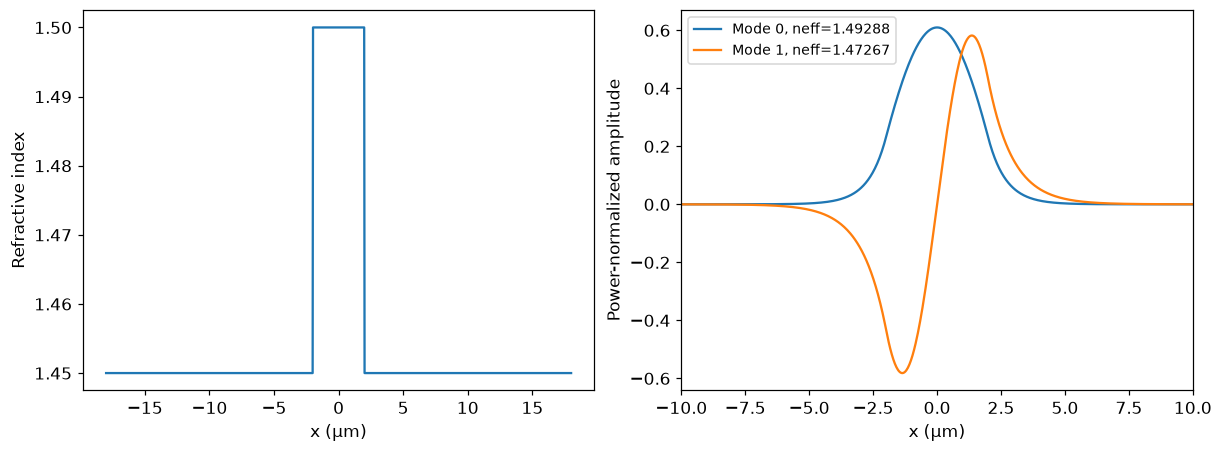

Relative matrix residual: 1.969507630389809e-14 Fundamental neff error: 2.547710474098963e-05


In [2]:
from scipy.linalg import eigh_tridiagonal
from scipy.optimize import brentq
wavelength=1.55;k0=2*np.pi/wavelength
ncore=1.5;nclad=1.45;width=4.
x=np.linspace(-18,18,1201);dx=x[1]-x[0]
index=np.where(abs(x)<width/2,ncore,nclad)
def eigenmodes(index):
    diagonal=-2/dx**2+k0**2*index[1:-1]**2
    off=np.full(len(diagonal)-1,1/dx**2)
    values,vectors=eigh_tridiagonal(diagonal,off,select="v",select_range=((k0*nclad)**2,(k0*ncore)**2))
    order=np.argsort(values)[::-1]
    return values[order],np.pad(vectors[:,order],((1,1),(0,0)))/np.sqrt(dx),diagonal,off
values,modes,diagonal,off=eigenmodes(index)
neff=np.sqrt(values)/k0
assert np.all((neff>nclad)&(neff<ncore))
assert np.max(abs(modes.T@modes*dx-np.eye(len(values))))<1e-12
residual=diagonal[:,None]*modes[1:-1]
residual[1:]+=off[:,None]*modes[1:-2]
residual[:-1]+=off[:,None]*modes[2:-1]
res=np.linalg.norm(residual-modes[1:-1]*values)/np.linalg.norm(modes[1:-1]*values)
assert res<1e-10
a=width/2;V=k0*a*np.sqrt(ncore*ncore-nclad*nclad)
u0=brentq(lambda u:u*np.tan(u)-np.sqrt(V*V-u*u),1e-9,min(V,np.pi/2)-1e-9)
analytic=np.sqrt(ncore*ncore-(u0/(k0*a))**2)
assert abs(neff[0]-analytic)<2e-4
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(x,index);ax[0].set(xlabel="x (μm)",ylabel="Refractive index")
for j in range(len(values)):
    ax[1].plot(x,modes[:,j],label=f"Mode {j}, neff={neff[j]:.5f}")
ax[1].set(xlim=(-10,10),xlabel="x (μm)",ylabel="Power-normalized amplitude");ax[1].legend(fontsize=9)
show(fig,"01-slab-modes")
print("Relative matrix residual:",res,"Fundamental neff error:",abs(neff[0]-analytic))

## 2 · Coupling is beating between supermodes

Two nearby guides have even and odd collective modes with propagation constants β₊, β₋.
A suitable sum localizes the initial field in one guide. Their relative phase changes
with z, moving power between guides. $\kappa=|\beta_+-\beta_-|/2$ and
the complete-transfer length is $\pi/(2\kappa)$ in the two-mode approximation.

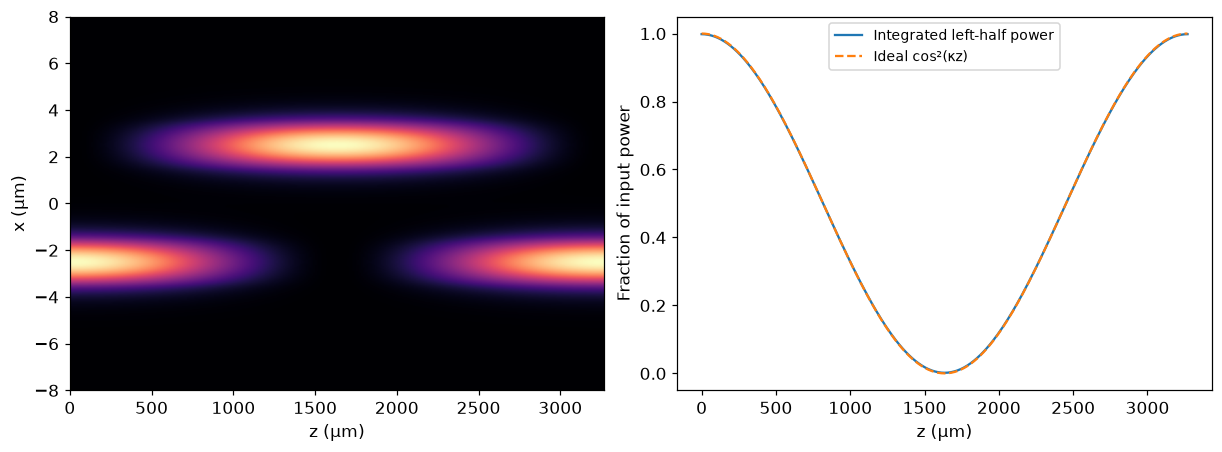

Computed κ: 0.0009608373981668805 μm⁻¹; transfer length: 1634.8201368844689 μm


In [3]:
separation=5.;guide_width=2.
double_index=np.where((abs(x-separation/2)<guide_width/2)|(abs(x+separation/2)<guide_width/2),ncore,nclad)
v,m,_,_=eigenmodes(double_index)
beta=np.sqrt(v[:2]);u=m[:,:2].copy()
# Choose signs so the initial sum is localized predominantly in the left guide.
if np.sum(u[x<0,0]*u[x<0,1])<0:u[:,1]*=-1
kappa=abs(beta[0]-beta[1])/2;transfer=np.pi/(2*kappa)
z=np.linspace(0,2*transfer,301)
field=(u[:,0,None]*np.exp(1j*beta[0]*z)+u[:,1,None]*np.exp(1j*beta[1]*z))/np.sqrt(2)
total=np.sum(abs(field)**2,axis=0)*dx
assert np.max(abs(total-1))<1e-12
left=np.sum(abs(field[x<0])**2,axis=0)*dx
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].imshow(abs(field)**2,origin="lower",aspect="auto",extent=[z[0],z[-1],x[0],x[-1]],cmap="magma")
ax[0].set(ylim=(-8,8),xlabel="z (μm)",ylabel="x (μm)")
ax[1].plot(z,left,label="Integrated left-half power")
ax[1].plot(z,np.cos(kappa*z)**2,"--",label="Ideal cos²(κz)")
ax[1].set(xlabel="z (μm)",ylabel="Fraction of input power");ax[1].legend(fontsize=9)
show(fig,"02-supermode-beating")
print("Computed κ:",kappa,"μm⁻¹; transfer length:",transfer,"μm")

## 3 · A ring adds repeated round trips

Let r be real amplitude self-coupling and a the amplitude surviving one round trip.
With a lossless coupler, the through-port amplitude is $(r-ae^{i\phi})/(1-rae^{i\phi})$.
The circulating amplitude is $i\sqrt{1-r^2}/(1-rae^{i\phi})$, up to phase convention.
A large circulating intensity does not violate energy conservation: energy is stored.

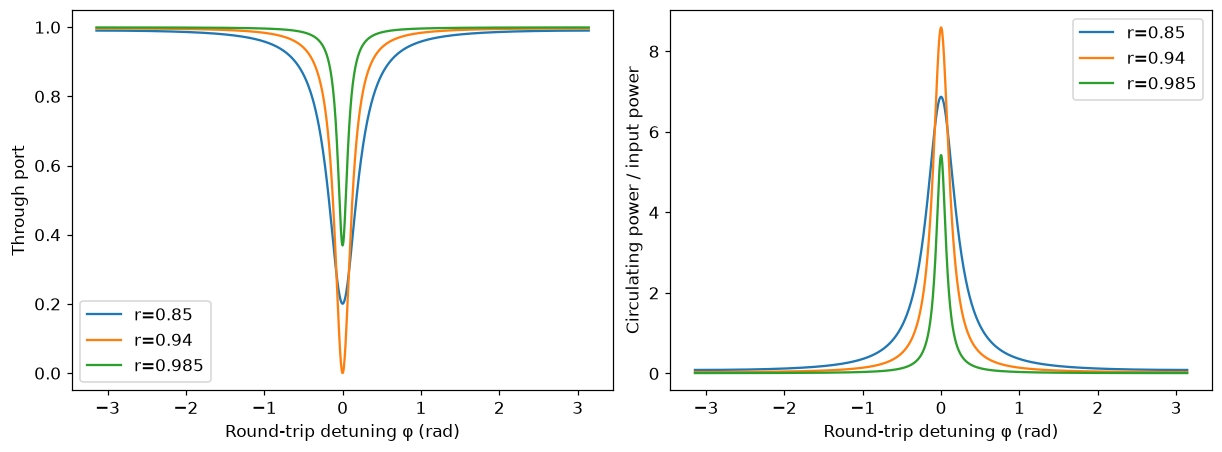

In [4]:
phi=np.linspace(-np.pi,np.pi,1201);a=.94
def ring(phi,r,a):
    den=1+(r*a)**2-2*r*a*np.cos(phi)
    return (r*r+a*a-2*r*a*np.cos(phi))/den,(1-r*r)/den
fig,ax=plt.subplots(1,2,figsize=(11,4))
for r in [.85,.94,.985]:
    T,C=ring(phi,r,a)
    ax[0].plot(phi,T,label=f"r={r}");ax[1].plot(phi,C,label=f"r={r}")
    assert np.max(abs(T+(1-a*a)*C-1))<1e-12
assert abs(ring(0,a,a)[0])<1e-12
assert np.max(abs(ring(phi,.8,1)[0]-1))<1e-12
for axis,title in zip(ax,["Through port","Circulating power / input power"]):
    axis.set(xlabel="Round-trip detuning φ (rad)",ylabel=title);axis.legend()
show(fig,"03-ring-resonance")

## Optional extension · A paraxial beam-propagation step

Remove the rapid carrier $e^{i k_0n_0z}$ and neglect the second z derivative of its envelope.
A split-step Fourier method alternates transverse diffraction and index phase. Its real
index factors preserve the discrete norm. This does not make BPM a full Maxwell solver:
back-reflection, large angles, and rapid longitudinal changes violate the approximation.

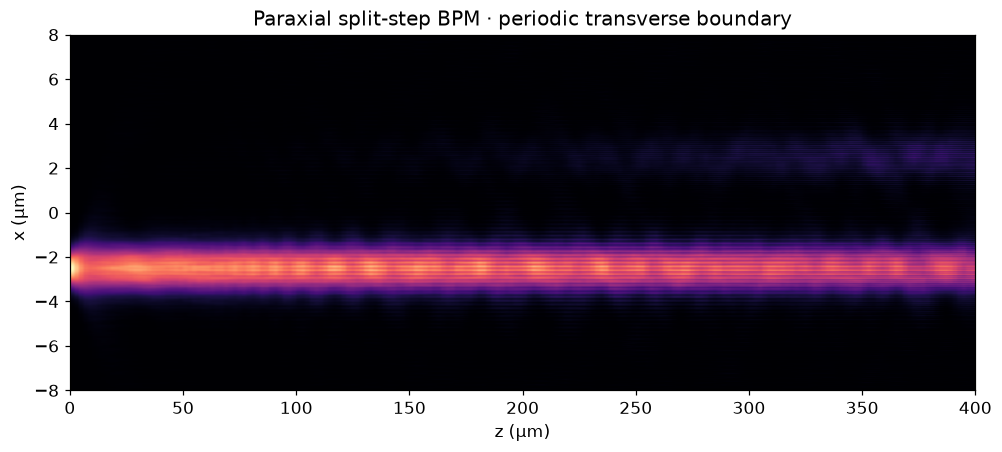

In [5]:
n0=nclad;fx=np.fft.fftfreq(len(x),dx);dz=.5
beam=np.exp(-((x+separation/2)/1.1)**2).astype(complex)
beam/=np.sqrt(np.sum(abs(beam)**2)*dx)
potential=np.exp(1j*k0*(double_index**2-n0**2)/(2*n0)*dz/2)
diffraction=np.exp(-1j*(2*np.pi*fx)**2/(2*k0*n0)*dz)
snapshots=[]
for step in range(800):
    beam*=potential
    beam=np.fft.ifft(np.fft.fft(beam)*diffraction)*potential
    if step%4==0:snapshots.append(abs(beam)**2)
assert abs(np.sum(abs(beam)**2)*dx-1)<1e-11
fig,ax=plt.subplots(figsize=(9,4))
ax.imshow(np.asarray(snapshots).T,origin="lower",aspect="auto",extent=[0,400,x[0],x[-1]],cmap="magma")
ax.set(ylim=(-8,8),xlabel="z (μm)",ylabel="x (μm)",title="Paraxial split-step BPM · periodic transverse boundary")
show(fig,"04-bpm-extension")

## A short lab report

**1. Check a mode.** Report an effective index, eigen-equation residual, and sensitivity to window size.

**2. Predict a coupler.** Compute the two supermode propagation constants and predict the first complete-transfer distance.

**3. Track energy storage.** Compare through-port power, circulating power, and decay after drive removal.

### Worked reasoning

**Check a mode.** The residual tests the discrete eigenproblem. Enlarging the window checks whether artificial boundaries disturb the physical tail.

**Predict a coupler.** κ = (βs − βa)/2, so L = π/|βs − βa| for the ideal symmetric two-mode system.

**Track energy storage.** Stored power can be larger than incident power through repeated coherent accumulation; decay and dissipation still obey energy balance.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [MIT OpenCourseWare · Dielectric waveguides](https://ocw.mit.edu/courses/6-974-fundamentals-of-photonics-quantum-electronics-spring-2006/pages/lecture-notes/)
- [SciPy · Hermitian eigenproblems](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.eigh.html)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [6]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 4 figures in e08_figures.zip


/tmp/optics-notebooks-xppq4daw/E08/e08_figures.zip